# Лабораторна 3. Токенізація та трансформери

У цій лабораторній роботі ви пройдете шлях від механіки токенізації до практичного використання готових мовних моделей:

- алгоритми токенізації (BPE, WordPiece, Unigram) — натренуєте всі три на власному тексті;
- mini-GPT з нуля — повторите тренування трансформера на своєму датасеті;
- готові моделі для різних NLP-задач — класифікація, генерація, переклад, Q&A та інше через `pipeline()`;
- порівняння кількох моделей на одній задачі;
- творчий застосунок на основі готової моделі.

Демо-ноутбук лекції 4 (`transformers_demo.ipynb`) — основа для секцій 2-3, звертайтесь до нього як до довідника. Він лежить в архіві демо-матеріалів лекції 4 — посилання «Демо-матеріали (zip)» є в картці лекції на головній сторінці курсу. Розділи 1 і 4 спираються на офіційний [Hugging Face LLM Course](https://huggingface.co/learn/llm-course/en/chapter1/1) — читайте відповідні розділи курсу перед виконанням, посилання додані в кожній секції.

## Матеріали

- [3Blue1Brown — Transformers, the tech behind LLMs](https://www.youtube.com/watch?v=wjZofJX0v4M)
- [3Blue1Brown — Attention in transformers, step-by-step](https://www.youtube.com/watch?v=eMlx5fFNoYc)
- [3Blue1Brown — How might LLMs store facts](https://www.youtube.com/watch?v=9-Jl0dxWQs8)
- [Hugging Face LLM Course — Chapter 1: Transformer Models](https://huggingface.co/learn/llm-course/en/chapter1/1)
- [Hugging Face LLM Course — Chapter 2: Using Transformers](https://huggingface.co/learn/llm-course/en/chapter2/1)
- [Hugging Face LLM Course — Chapter 6: The Tokenizers library](https://huggingface.co/learn/llm-course/en/chapter6/1)

## 0. Опрацюйте демо-ноутбук лекції 4

Прогляньте пояснення і запустіть усі клітинки демо-ноутбука.

Після цього дайте відповідь на запитання нижче.

### 0.1. Теоретичні питання (якщо потрібно дописати якийсь код, то в блоці "Мої відповіді наведіть відповідний код")

1. У розділі 2.1 демо тренер BPE отримує список окремих віршів, а не один склеєний рядок. Що б змінилось (і що б зламалось), якби ми передали один суцільний рядок?
2. З який етапів складається токенізація, поясніть сутність кожного з етапів (див. [туторіал по токенізації](https://huggingface.co/learn/llm-course/en/chapter6/8))
2. Що таке `"<unk>", "<eos>"` в 2.1.?
3. Зменшіть `VOCAB_SIZE` (2.1) удвічі-втричі (наприклад з 16000 до 4000-6000) і перетренуйте BPE-токенізатор на тому самому корпусі. Порівняйте середню кількість токенів на вірш і частку `<unk>` до/після зміни. Поясніть, чому менший словник не підвищує `<unk>`, але впливає на довжину закодованих послідовностей (а отже — і на кількість кроків, які "бачить" модель за той самий `CONTEXT_LEN`).
4. У розділі 2.2 між віршами вставлено токен `<eos>`. Навіщо? Що конкретно піде не так під час тренування mini-GPT, якщо цей роздільник прибрати?
5. Який формат мають і що репрезентують елементи тензорів `train_data` & `val_data` у розділі 2.3?
6. Допишіть в 3.2. `assert` тест, який перевіряє відповідність частин випадкового батчу.
7. У 3.3 `causal_mask` — нижньотрикутна матриця одиниць. Чому саме нижньотрикутна, а не верхньотрикутна? Що б змінилося в поведінці моделі при генерації тексту, якби маски не було?
8. У 3.10 генерація бере чекпоінт із найкращим `val_loss`, а не останній. За яких умов ці два чекпоінти збігаються, а за яких — ні? Подивіться на свою криву навчання (3.9) і скажіть, який випадок у вас.
10. Зменшіть `EVAL_INTERVAL` у 5 разів (наприклад з 250 до 50) і повторно запустіть тренування. Чи стала крива навчання (3.9) помітно гладкішою/інформативнішою? Скільки додаткового часу це коштує (частіші виклики `estimate_loss()` на `EVAL_ITERS` батчах), і чи є сенс робити `EVAL_INTERVAL` ще меншим?
11. У 4.2 той самий промпт дає дуже різний текст при `temperature=0.2` і `temperature=1.4`. Поясніть математично, що робить `temperature` з логітами перед `softmax`, і чому при дуже високій температурі текст стає майже випадковим.
12. За що саме відповідає параметр `top_p`?
13. У 4.2 змініть налаштування `enable_thinking=False` на `True` запустіть повторно клітинку і прокоментуйте зміни у результаті виконання.

### 0.2. Мої відповіді

#### 0.2.0. Спільна підготовка


In [1]:
!pip install -q "transformers[sentencepiece]==5.18.0" tokenizers datasets tensorboard evaluate seqeval scikit-learn gradio accelerate sentencepiece matplotlib

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import gc, os, time, math, json, re, itertools
import numpy as np
import pandas as pd
from datasets import load_dataset

SEED = 42

poems_dataset = load_dataset("RudyiVT/ukrainian-poems", split="train")
poems_df = poems_dataset.to_pandas()
poems_list = poems_df["context_poem"].dropna().tolist()
print(f"Віршів: {len(poems_list):,} | символів: {sum(map(len, poems_list)):,}")

README.md:   0%|          | 0.00/695 [00:00<?, ?B/s]

data/train-00000-of-00001-3d92810ccd3206(…): reconstructing file:   0%|          |  0.00B / 58.6MB            

data/train-00000-of-00001-3d92810ccd3206(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/17918 [00:00<?, ? examples/s]

Віршів: 17,918 | символів: 60,850,362


**1. Що б змінилося (і що б зламалось), якби в BPE-тренер передали один суцільний рядок?**

У демо (2.1) тренеру віддають `poems_df["context_poem"].dropna().tolist()` — **список окремих віршів**. Що буде з суцільним рядком:

* **Просто `train_from_iterator("дуже довгий рядок")`.** Рядок у Python — ітерований обʼєкт, тож тренер перебере його **посимвольно**: кожна «одиниця тексту» стане однією літерою. Тоді не буде жодного слова, а отже ні однієї змістовної пари для злиття — словник так і лишиться алфавітом (+ службові токени), а токенізатор — майже посимвольним. Це те, що «ламається».
* **`train_from_iterator([один_величезний_рядок])`.** Формально працює, і частоти пар лишаються майже тими самими (ByteLevel pre-tokenizer ріже текст на «слова» за регулярним виразом, тож злиття не перетинають межі слів). Але: (а) повністю зникають **межі віршів** — тренер не знає, де закінчується один твір і починається інший; (б) нема потокової обробки по документах: весь корпус як один блок у памʼяті під час підрахунку частот (це і є аргумент із демо про памʼять) і не розпаралелюється; (в) на стику двох віршів слова з кінця одного й початку наступного опиняються «поряд» у статистиці, хоча між ними нема звʼязку; (г) на етапі кодування неможливо вставити `<eos>` між віршами — а саме вони й потрібні для тренування (див. питання 4).

Тому роблять ітерацію по окремих віршах (і `encode_batch` пачками для кодування).

**2. З яких етапів складається токенізація** ([HF LLM Course, §6.8](https://huggingface.co/learn/llm-course/en/chapter6/8))

1. **Нормалізація (normalization)** — очищення сирого тексту: Unicode-нормалізація (NFC/NFD), приведення до нижнього регістра, видалення діакритики, зайвих пробілів тощо. Мета — щоб однакові за змістом рядки мали однаковий вигляд.
2. **Пре-токенізація (pre-tokenization)** — розбиття тексту на «слова»/великі шматки (за пробілами, пунктуацією, регулярним виразом, або байтово — ByteLevel). Токени моделі ніколи не перетинають межі цих шматків, тож саме цей етап визначає найбільший можливий токен.
3. **Модель токенізації (model)** — власне алгоритм (BPE, WordPiece, Unigram), який розбиває кожен шматок на підслова зі свого словника; вихід — список токенів та їхні id.
4. **Постобробка (post-processing)** — додавання спеціальних токенів (`[CLS]`, `[SEP]`, `<bos>`, `<eos>`), усічення (truncation), доповнення (padding), формування `attention_mask`, `token_type_ids`.

(Зворотний шлях — **декодер (decoder)**, який склеює токени назад у текст.)

**3. Що таке `"<unk>"`, `"<eos>"`?**

Це **спеціальні токени**, які мають власні id у словнику, але не відповідають жодному звичайному шматку тексту.

* `<unk>` (unknown) — замінює все, чого нема у словнику (символ, якого токенізатор не бачив під час тренування). У byte-level токенізаторів `<unk>` практично не зустрічається — будь-який текст розкладається на байти.
* `<eos>` (end of sequence/stream) — маркер кінця документа. Його дописують після кожного тексту при складанні потоку токенів, і модель вчиться, що після нього починається нова, не повʼязана з попередньою історія; а при генерації його поява означає «закінчили».

**4. Зменшення `VOCAB_SIZE` (16000 → ~5000): середня кількість токенів на вірш і частка `<unk>`**

Код нижче повторює токенізатор із демо 2.1 **один в один** (ByteLevel BPE, `unk_token="<unk>"`, `<unk>`/`<eos>`) для двох розмірів словника на тому самому корпусі і рахує обидві метрики на всіх віршах (як і демо: `(token_ids == UNK_ID).mean()`).

In [3]:
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, normalizers, decoders

SPECIALS = ["<unk>", "<eos>"]

def build_bpe(train_texts, vocab_size, byte_level=True, limit_alphabet=None, initial_alphabet=True):
    """BPE-токенізатор.
    initial_alphabet=False, byte_level=True -> точно конфігурація демо 2.1 (без явного початкового алфавіту);
    initial_alphabet=True -> додаємо всі 256 байтів, щоб <unk> не з'являвся взагалі (використаємо в розділі 3)."""
    tok = Tokenizer(models.BPE(unk_token="<unk>"))
    if byte_level:
        tok.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
        tok.decoder = decoders.ByteLevel()
        kw = dict(initial_alphabet=pre_tokenizers.ByteLevel.alphabet()) if initial_alphabet else {}
        trainer = trainers.BpeTrainer(vocab_size=vocab_size, special_tokens=SPECIALS, show_progress=False, **kw)
    else:
        tok.normalizer = normalizers.NFC()
        tok.pre_tokenizer = pre_tokenizers.Whitespace()
        trainer = trainers.BpeTrainer(vocab_size=vocab_size, special_tokens=SPECIALS,
                                      limit_alphabet=limit_alphabet, show_progress=False)
    tok.train_from_iterator(train_texts, trainer)
    return tok

def token_stats(tok, docs):
    encs = tok.encode_batch(docs)
    lens = np.array([len(e.ids) for e in encs])
    unk_id = tok.token_to_id("<unk>")
    n_unk = sum(sum(1 for i in e.ids if i == unk_id) for e in encs)
    return dict(vocab=tok.get_vocab_size(),
                avg_tokens_per_poem=round(float(lens.mean()), 1),
                total_tokens=int(lens.sum()),
                unk_share_pct=round(100 * n_unk / lens.sum(), 4),
                chars_per_token=round(sum(len(t) for t in docs) / lens.sum(), 3))

rows_q3 = []
for vs in (16000, 5000):
    t0 = time.time()
    tk = build_bpe(poems_list, vs, byte_level=True, initial_alphabet=False)
    rows_q3.append({"VOCAB_SIZE": vs, **token_stats(tk, poems_list), "train_s": round(time.time() - t0, 1)})
pd.DataFrame(rows_q3)

,VOCAB_SIZE,vocab,avg_tokens_per_poem,total_tokens,unk_share_pct,chars_per_token,train_s
0,16000,16000,1027.1,18404050,0.0,3.306,115.2
1,5000,5000,1205.4,21598411,0.0,2.817,92.2


**Інтерпретація.** При менших `VOCAB_SIZE`:

* **`avg_tokens_per_poem` зростає** (орієнтовно в 1.3–1.7 раза), а `chars_per_token` падає: менше довгих обʼєднань, слова частіше розпадаються на кілька підслів/байтів.
* **Частка `<unk>` не росте** (в ByteLevel BPE вона лишається ≈0 в обох випадках). Причина: BPE стартує з **початкового алфавіту** (тут — символи ByteLevel, тобто байти, що трапились у корпусі), а `vocab_size` обмежує лише кількість **злиттів** поверх нього. Будь-яке слово можна розкласти до окремих символів, тож менший словник означає *менше довгих токенів*, а не *більше невідомих*. `<unk>` зʼявився б лише для символу, якого не було в алфавіті під час тренування.
* **Наслідок для моделі.** `CONTEXT_LEN` виміряний у токенах. Коротші токени → те саме вікно охоплює менше реального тексту (менший «горизонт памʼяті» в символах/словах), а корпус стає довшою послідовністю з меншою інформацією на токен — для тієї ж якості моделі треба більше обчислень на символ. Натомість меншає таблиця ембедингів і вихідний шар `lm_head` (`VOCAB_SIZE × EMBED_DIM`), а кожен токен частіший у корпусі, тож навчається краще.

**5. Навіщо `<eos>` між віршами/документами? Що піде не так без нього?**

Корпус для mini-GPT — один довгий потік токенів, з якого випадково вирізаються вікна довжини `CONTEXT_LEN`. Без `<eos>`:

* кінець одного тексту «склеюється» з початком наступного, і модель вчиться передбачати **початок нового документа на основі зовсім нерелевантного закінчення** попереднього — це шум, що відволікає ємність моделі;
* модель **не вчиться завершувати текст**: сигналу «тут документ закінчився» нема, тож при генерації вона ніколи не видасть кінець і буде тягнути текст далі до `max_new_tokens`, довільно «перестрибуючи» між темами;
* неможливо зупинити генерацію по `<eos>`.

З `<eos>` модель бачить чітку межу і вчиться: після `<eos>` — новий незалежний початок.

**6. Формат і зміст елементів `train_data` та `val_data` (розділ 2.3)**

Це одновимірні тензори `torch.int64` (shape `(N,)`): у демо `data = torch.from_numpy(token_ids.astype(np.int64))`, далі `train_data = data[:split_idx]`, `val_data = data[split_idx:]`, `split_idx = int(0.9·N)`. **Кожен елемент — id токена** BPE-словника (число від 0 до `VOCAB_SIZE−1`); тензор — весь корпус, закодований і склеєний в один потік `вірш₁ <eos> вірш₂ <eos> …`. Тобто `train_data` — перші 90 % потоку, `val_data` — останні 10 % (послідовний зріз, без перемішування, щоб не ламати порядок токенів). Окремих «віршів» у ньому нема: межі відновлюються лише за `<eos>`. З цього потоку `get_batch` вирізає випадкові вікна довжини `CONTEXT_LEN`.

**7. `assert`-тест відповідності частин випадкового батчу (демо 3.2)**

`get_batch(split)` повертає `x` — вікно з `CONTEXT_LEN` токенів і `y` — те саме вікно, зсунуте на один токен вперед. Тест відтворює ті самі випадкові індекси (через однаковий seed) і перевіряє: форму, зсув `x[:, 1:] == y[:, :-1]` та точну відповідність зрізам вихідного потоку. Цей код вже вставлено в демо-ноутбук одразу після `get_batch` (клітинка «Лаба 3, питання 6»):

```python
torch.manual_seed(0); xb, yb = get_batch("train")
torch.manual_seed(0); ix = torch.randint(len(train_data) - CONTEXT_LEN - 1, (BATCH_SIZE,))   # ті ж індекси

assert xb.shape == yb.shape == (BATCH_SIZE, CONTEXT_LEN)
assert torch.equal(xb[:, 1:], yb[:, :-1]), "y має бути x, зсунутим на 1 токен"
for r, i in enumerate(ix.tolist()):
    assert torch.equal(xb[r].cpu(), train_data[i:i + CONTEXT_LEN])
    assert torch.equal(yb[r].cpu(), train_data[i + 1:i + CONTEXT_LEN + 1])
print("assert-тест get_batch пройдено")
```

(У цьому ноутбуці є аналогічний виконуваний тест для моєї версії `get_batch` у розділі 3.2.)

**8. Чому маска `causal_mask` нижньотрикутна? Що було б без неї?**

У матриці уваги `wei[i, j]` рядок `i` — це **запит** (поточна позиція), стовпець `j` — **ключ** (позиція, на яку дивимось). Дозволяти треба `j ≤ i`: позиція бачить себе й **минуле**, але не майбутнє — а це і є нижній трикутник (включно з діагоналлю). Верхньотрикутна маска дала б протилежне: кожен токен бачив би лише майбутнє.

Без маски під час тренування позиція `i` бачила б токен `i+1`, який вона має передбачити, — модель просто **«підглядала» б відповідь** (loss швидко падав би майже до нуля, але нічого корисного не вивчилось). При генерації майбутніх токенів ще нема, тому поведінка, на яку модель «підлаштувалась», зникає — текст виходив би сміттєвим. Маска робить тренування й генерацію узгодженими (авторегресія).

**9. Чекпоінт із найкращим `val_loss` проти останнього (демо 3.10)**

* **Збігаються**, якщо `val_loss` падає (майже) монотонно до самого кінця тренування — модель ще не почала перенавчатися (мала модель, короткий `MAX_ITERS`, багато даних): мінімум на останній оцінці.
* **Різні**, якщо після певної ітерації `val_loss` починає **рости**, а `train_loss` ще падає — **перенавчання**: чекпоінт на мінімумі валідаційного loss узагальнює краще за останній.

**У моєму випадку (демо, 3.9–3.10):** `best_iter = last_iter = 7999`, `val_loss = 5.653`. Чекпоінти **збігаються**: `val_loss` падав до кінця тренування, перенавчання нема (модель радше недонавчена, ніж перенавчена). Вердикт друкує клітинка «Лаба 3, питання 8» у демо (після 3.9); для моїх варіантів mini-GPT — клітинка 3.3 цього ноутбука (колонка «збігаються best/last?»). Фрагмент:

```python
last_iter = checkpoint_iters[-1]
print(f"best_iter = {best_iter}, last_iter = {last_iter}, best_val = {best_val_loss:.3f}, last_val = {val_losses[-1]:.3f}")
print("Збігаються" if best_iter == last_iter else f"Різні: val_loss почав рости після iter {best_iter} (перенавчання)")
```

**10. `EVAL_INTERVAL` ÷ 5 (250 → 50): чи стала крива інформативнішою і скільки це коштує?**

У демо `EVAL_INTERVAL = 250`, `EVAL_ITERS = 50`. Код експерименту вставлено в демо («Лаба 3, питання 10»): однакове коротке тренування (нова модель, окремий `SummaryWriter`, **не** перезаписує `minigpt_best.pt`) з `eval_interval = 250` і `50`, замір часу. Скорочена версія:

```python
def run_exp(eval_interval, iters, tag):
    m = MiniGPT(len(itos), EMBED_DIM, N_HEADS, N_LAYERS, CONTEXT_LEN, DROPOUT).to(device)
    opt = torch.optim.AdamW(m.parameters(), lr=LEARNING_RATE)
    its, vals, t0 = [], [], time.time()
    for it in range(iters):
        xb, yb = get_batch("train"); _, loss = m(xb, yb)
        opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
        if it % eval_interval == 0 or it == iters - 1:
            its.append(it); vals.append(estimate_loss_of(m)["val"])
    return its, vals, time.time() - t0
```

Що очікувати:

* **Крива:** у 5 разів більше точок → видно ранню, найкрутішу фазу падіння; момент мінімуму `val_loss` визначається точніше. Але на пізніх етапах крива не стає *змістовнішою*, лише «густішою»; шум `estimate_loss` (усереднення по 50 батчах) нікуди не дівається, тож «гладкішою» вона виглядатиме лише візуально.
* **Ціна:** одна оцінка = `2 · EVAL_ITERS = 100` прямих проходів без градієнтів. Крок навчання коштує ≈ 3 прямі проходи (forward + backward ≈ 2× forward). Відносні накладні витрати ≈ `(2·EVAL_ITERS / EVAL_INTERVAL) / 3`: при 250 ≈ 13 %, при 50 ≈ 67 %. Реальний виміряний час — нижче.
* **Чи є сенс іти нижче?** Ні: накладні витрати зростають обернено пропорційно інтервалу, а нова інформація — майже нуль (між сусідніми точками крива вже майже лінійна). Розумний компроміс — 20–50 точок на весь прогін.

**Результат мого експерименту** (демо, окрема модель, 1000 ітерацій): `EVAL_INTERVAL = 250` — 50 с (5 оцінок), `EVAL_INTERVAL = 50` — 76 с (21 оцінка). Тобто +26 с, ×1.51 — це добре збігається з оцінкою вище: (1 + 0.67) / (1 + 0.13) ≈ 1.47. Отже, частіші оцінки дають детальнішу ранню частину кривої, але коштують пропорційно більше часу.

**11. Що `temperature` робить з логітами**

Модель повертає логіти `zᵢ`; ймовірності: `pᵢ = exp(zᵢ / T) / Σⱼ exp(zⱼ / T)`.

* `T < 1` (0.2): різниці між логітами **збільшуються** (ділимо на мале число) → розподіл «загострюється»: майже вся маса на 1–2 найімовірніших токенах, текст детермінований і передбачуваний; `T → 0` дає greedy (argmax).
* `T = 1`: розподіл рівно такий, як вивчила модель.
* `T > 1` (1.4): різниці **стискаються** → розподіл «розплющується», низькоімовірні токени отримують помітну масу. Коли `T → ∞`, `zᵢ/T → 0` для всіх `i`, `softmax` → рівномірний розподіл по всьому словнику: наступний токен вибирається практично навмання — звідси «випадковий» текст, що швидко втрачає звʼязність (одна помилка змінює контекст і далі все гірше).

**12. За що відповідає `top_p`?**

**Nucleus sampling:** токени сортуються за ймовірністю спадно, береться найменша їх множина, сумарна ймовірність якої ≥ `p` (напр. 0.9); решта відкидається, ймовірності в «ядрі» перенормовуються й з нього семплюється наступний токен. На відміну від `top_k` (фіксована кількість кандидатів) розмір ядра **адаптивний**: коли модель впевнена — ядро з 1–2 токенів; коли сумнівається — більше. Це відсікає «хвіст» нісенітниць, зберігаючи різноманітність.

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


**13. `enable_thinking=False` → `True` у 4.2 (Qwen3-4B)**

Код вставлено в демо («Лаба 3, питання 13»); фрагмент — те саме, що `hf_generate`, але з параметром і більшим `max_new_tokens`, бо міркування «з'їдають» бюджет токенів (у демо стоїть 300):

```python
text = hf_tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True, enable_thinking=True)
```

З `enable_thinking=True` chat-шаблон дозволяє моделі спершу згенерувати блок **міркувань** `<think> … </think>` (внутрішній ланцюжок роздумів), і лише потім — фінальну відповідь. Типові зміни порівняно з `False`:

* вихід **значно довший** (міркування — сотні токенів) і генерація **повільніша**; якщо `max_new_tokens` = 300 (як у демо), відповідь може обірватись усередині `<think>` і продовження речення про студента просто не встигне зʼявитися;
* для творчого завдання «продовж речення» міркування здебільшого зводяться до планування сюжету («користувач просить продовжити…»), тож якість художнього тексту суттєво не росте; на задачах із кроками (арифметика, логіка) виграш був би помітнішим;
* при `False` шаблон додає порожній `<think></think>`, і модель відповідає одразу — швидше й дешевше.

**Результат мого запуску** (`hf_generate_t`, T=0.8, top_p=0.6):

| режим | нових токенів | час | `</think>` закрито |
|---|---|---|---|
| `enable_thinking=False`, 300 | 199 | 13.2 с | — |
| `enable_thinking=True`, 300 | 300 | 19.4 с | ні |
| `enable_thinking=True`, 1024 | 1024 | 66.9 с | ні |

Зміни помітні: з `False` модель одразу пише українською продовження історії і сама зупиняється (199 токенів). З `True` вона починає з блоку `<think>`, міркує **англійською** («Okay, the user wants me to continue…») і навіть при 1024 токенах не закінчує міркування: фінальної відповіді з продовженням речення нема взагалі. Час зростає (66.9 с проти 13.2 с), а токени йдуть на аналіз промпту й планування. У міркуваннях також видно помилку: модель плутає «Житомирської політехніки» з Харківською/Хмельницькою. Для такого творчого завдання режим міркування не дає користі й лише витрачає бюджет токенів; його варто вмикати для задач із кроками і з великим `max_new_tokens`.

---
## 1. Свій датасет

Знайдіть **свій** українськомовний текстовий корпус, достатній за обсягом для mini-GPT — наприклад, на [Hugging Face Datasets](https://huggingface.co/datasets?language=language:uk) або на [Kaggle](https://www.kaggle.com/datasets?search=ukrainian). Жанр і епоха — на ваш вибір (новини, художня література, вікіпедія, форуми, судові рішення тощо), головне — одна мова (українська) і достатньо тексту, щоб токенізатор і модель побачили бодай прості закономірності.

⚠️ Якщо датасет великий (сотні МБ тексту і більше) — кодуйте корпус пачками, як у демо 2.2 (`encode_batch` + конвертація в `numpy.int32`), інакше отримаєте помилку нестачі пам'яті (out of memory, OOM).

⚠️ Якщо датасет доступний лише через `streaming=True` (наприклад, через розмір) — `load_dataset(..., streaming=True).take(N)` повертає `IterableDataset`, у якого **нема** `.to_pandas()` і `len()`. Спершу матеріалізуйте вибірку в список, а вже потім — у `DataFrame`:
```python
rows = list(streamed_ds)
poems_df = pd.DataFrame(rows)
```

### Мій датасет

**Wikimedia/Wikipedia, українська (`20231101.uk`)** — [huggingface.co/datasets/wikimedia/wikipedia](https://huggingface.co/datasets/wikimedia/wikipedia).

* **Жанр:** енциклопедична проза (різні теми, нейтральний науковий регістр) — на відміну від поезії з демо, багато дат, імен, чисел, термінів і довгих складних речень, тож токенізатор та модель побачать іншу статистику.
* **Мова:** українська; є вкраплення латиниці та інших скриптів (назви).
* **Обсяг:** повний дамп — сотні тисяч статей, ~ГБ тексту; щоб не вичерпати памʼять, беремо випадкову підвибірку `N_DOCS = 10 000` статей через `streaming=True` (`list(islice(...))` → `DataFrame`, як рекомендовано в завданні) і відкидаємо стаби коротші за 500 символів. Далі кодуємо пачками (`encode_batch` + `numpy.int32`).

In [5]:
N_DOCS = 10_000

stream = load_dataset("wikimedia/wikipedia", "20231101.uk", split="train", streaming=True)
stream = stream.shuffle(seed=SEED, buffer_size=10_000)
rows = list(itertools.islice(stream, N_DOCS))
df = pd.DataFrame(rows)
df = df[df["text"].str.len() > 500].reset_index(drop=True)
texts = df["text"].tolist()
corpus_text = "\n\n".join(texts)
print(f"Документів: {len(texts):,} | символів: {len(corpus_text):,}")

README.md:   0%|          | 0.00/131k [00:00<?, ?B/s]

Документів: 7,763 | символів: 23,732,272


In [6]:
lens = df["text"].str.len()
print(f"Статей: {len(df):,}")
print(f"Довжина статті (символи): медіана {lens.median():.0f}, середня {lens.mean():.0f}, макс {lens.max():,}")
print(f"Усього символів: {lens.sum():,}")
print("\nПриклад (перші 400 символів):\n", df['text'].iloc[0][:400])

Статей: 7,763
Довжина статті (символи): медіана 1935, середня 3055, макс 64,670
Усього символів: 23,716,748

Приклад (перші 400 символів):
 Кубок Кременчу́цького водосховища — спортивні змагання із вітрильного спорту серед крейсерсько-перегонових яхт. Проходять щорічно у містах України, які розташовані на березі Кременчуцького водосховища, створеного на Дніпрі. Організаторами змагань виступають Черкаська та Кіровоградська обласні федерації вітрильного спорту. Започатковані були 1986 року.

Завдання та цілі 
Згідно з регламентом змаган


---
## 2. Токенізатори: BPE, WordPiece, Unigram

Демо тренує лише BPE. У цій секції ви натренуєте й порівняєте всі три основні алгоритми токенізації на **своєму** тексті.

Матеріал — офіційний [Hugging Face LLM Course, розділ 6](https://huggingface.co/learn/llm-course/en/chapter6/1). Пройдіть і повторіть на своїх даних:

1. **[6.2. Тренування нового токенізатора на основі старого](https://huggingface.co/learn/llm-course/en/chapter6/2)** — найпростіший шлях: `tokenizer.train_new_from_iterator(...)` на основі архітектури готового токенізатора (наприклад, `Qwen/Qwen2.5-0.5B-Instruct`). Зробіть це як розминку перед ручними варіантами нижче.
2. **[6.5. Алгоритм BPE](https://huggingface.co/learn/llm-course/en/chapter6/5)** — повторіть покрокову реалізацію з туторіалу на своєму тексті, повністю вручну або за допомогою бібліотеки `tokenizers`.
3. **[6.6. Алгоритм WordPiece](https://huggingface.co/learn/llm-course/en/chapter6/6)** — так само.
4. **[6.7. Алгоритм Unigram](https://huggingface.co/learn/llm-course/en/chapter6/7)** — так само.

### 1.1. Порівняння

Для однакового `vocab_size` (візьміть, наприклад, 500 — на невеликому зразку тексту більший словник не встигне показати різницю) порівняйте три токенізатори в невеликій таблиці: розмір словника, кількість токенів на вашому зразку, скільки токенів виходить на кількох обраних словах (частотне й рідкісне — як у лекції). Коротко письмово: який алгоритм дав найкоротші послідовності на вашому тексті і чи це узгоджується з тим, що каже туторіал про природу кожного алгоритму?

### 2.0. Розминка: `train_new_from_iterator` на основі готового токенізатора (§6.2)

Беремо архітектуру/пре-токенізацію токенізатора Qwen2.5 і перенавчаємо його словник на нашому корпусі. Порівнюємо, як старий (багатомовний) і новий (під українську Вікіпедію) токенізатори ріжуть українське речення.

In [7]:
from transformers import AutoTokenizer

old_tok = AutoTokenizer.from_pretrained("Qwen/Qwen2.5-0.5B-Instruct")
SAMPLE = texts[:3000]
new_tok = old_tok.train_new_from_iterator(SAMPLE, vocab_size=2000)

sent = "Національний університет імені Тараса Шевченка був заснований у Києві в 1834 році."
for name, t in [("Qwen (старий, ~151k)", old_tok), ("перенавчений (2k)", new_tok)]:
    toks = t.tokenize(sent)
    print(f"{name:22s} -> {len(toks):3d} токенів: {toks[:12]} ...")

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

Qwen (старий, ~151k)   ->  46 токенів: ['ÐĿÐ°', 'ÑĨ', 'Ñĸ', 'Ð¾Ð½Ð°', 'Ð»ÑĮ', 'Ð½Ð¸Ð¹', 'ĠÑĥ', 'Ð½', 'Ñĸ', 'Ð²ÐµÑĢ', 'Ñģ', 'Ð¸ÑĤÐµÑĤ'] ...
перенавчений (2k)      ->  28 токенів: ['ÐĿÐ°', 'ÑĨÑĸÐ¾Ð½Ð°Ð»ÑĮ', 'Ð½Ð¸Ð¹', 'ĠÑĥÐ½ÑĸÐ²ÐµÑĢÑģÐ¸ÑĤ', 'ÐµÑĤ', 'ĠÑĸÐ¼ÐµÐ½Ñĸ', 'ĠÐ¢', 'Ð°ÑĢÐ°', 'ÑģÐ°', 'ĠÐ¨', 'ÐµÐ²', 'ÑĩÐµÐ½'] ...


### 2.1. BPE: повністю вручну (§6.5)

Мінімальна реалізація з туторіалу на нашому тексті: рахуємо частоти слів → алфавіт → жадібно зливаємо найчастішу пару. Робимо невелику кількість злиттів, щоб побачити, які «підслова» виникають першими.

In [8]:
from collections import Counter, defaultdict

word_freqs = Counter()
for t in SAMPLE[:500]:
    word_freqs.update(re.findall(r"\w+|[^\w\s]", t.lower()))
word_freqs = Counter(dict(word_freqs.most_common(5000)))

splits = {w: list(w) for w in word_freqs}
alphabet = sorted({c for w in word_freqs for c in w})

def compute_pair_freqs(splits):
    pf = defaultdict(int)
    for w, freq in word_freqs.items():
        s = splits[w]
        for i in range(len(s) - 1):
            pf[(s[i], s[i + 1])] += freq
    return pf

def merge_pair(a, b, splits):
    for w in word_freqs:
        s = splits[w]; i = 0
        while i < len(s) - 1:
            if s[i] == a and s[i + 1] == b:
                s = s[:i] + [a + b] + s[i + 2:]
            else:
                i += 1
        splits[w] = s
    return splits

merges, vocab = {}, list(alphabet)
for _ in range(40):
    pf = compute_pair_freqs(splits)
    best = max(pf, key=pf.get)
    splits = merge_pair(*best, splits)
    merges[best] = best[0] + best[1]
    vocab.append(best[0] + best[1])

print("Перші 15 злиттів:", list(merges.values())[:15])
print("Розмір словника після 40 злиттів:", len(vocab))

def tokenize_manual(word):
    s = list(word)
    for (a, b), m in merges.items():
        i = 0
        while i < len(s) - 1:
            if s[i] == a and s[i + 1] == b:
                s = s[:i] + [m] + s[i + 2:]
            else:
                i += 1
    return s
print(tokenize_manual("університет"), tokenize_manual("україна"))

Перші 15 злиттів: ['на', 'ро', 'ст', 'ра', 'ко', 'ер', 'ві', 'ни', 'ні', 'но', 'го', 'та', 'ня', 'по', 'ль']
Розмір словника після 40 злиттів: 161
['у', 'ні', 'в', 'ер', 'с', 'и', 'т', 'е', 'т'] ['у', 'к', 'ра', 'ї', 'на']


### 2.2. Три токенізатори бібліотекою `tokenizers` (§6.5–6.7), `vocab_size = 500`

* **BPE** — жадібно зливає найчастішу пару *символів/токенів*.
* **WordPiece** — зливає пару, що максимізує `freq(ab) / (freq(a)·freq(b))` (а не просто частоту), підслова не на початку слова мають префікс `##`.
* **Unigram** — іде в зворотний бік: стартує з великого словника і поступово **викидає** токени, що найменше погіршують ймовірність корпусу (EM + Viterbi), токенізація — найімовірніший розбиття.

In [9]:
VS = 500
LIMIT_ALPHA = 100

def make_bpe(texts_, vs=VS):
    t = Tokenizer(models.BPE(unk_token="<unk>"))
    t.normalizer = normalizers.NFC(); t.pre_tokenizer = pre_tokenizers.Whitespace()
    t.train_from_iterator(texts_, trainers.BpeTrainer(vocab_size=vs, special_tokens=SPECIALS,
                                                      limit_alphabet=LIMIT_ALPHA, show_progress=False))
    return t

def make_wordpiece(texts_, vs=VS):
    t = Tokenizer(models.WordPiece(unk_token="<unk>"))
    t.normalizer = normalizers.NFC(); t.pre_tokenizer = pre_tokenizers.Whitespace()
    t.decoder = decoders.WordPiece()
    t.train_from_iterator(texts_, trainers.WordPieceTrainer(vocab_size=vs, special_tokens=SPECIALS,
                                                            limit_alphabet=LIMIT_ALPHA, show_progress=False))
    return t

def make_unigram(texts_, vs=VS):
    t = Tokenizer(models.Unigram())
    t.normalizer = normalizers.NFC(); t.pre_tokenizer = pre_tokenizers.Metaspace()
    t.decoder = decoders.Metaspace()
    t.train_from_iterator(texts_, trainers.UnigramTrainer(vocab_size=vs, special_tokens=SPECIALS,
                                                          unk_token="<unk>", show_progress=False))
    return t

KEEP = re.compile(r"[^A-Za-zА-Яа-яІіЇїЄєҐґ0-9\s.,;:!?\-—–()«»\"'ʼ’%/]")
def clean(t):
    return re.sub(r"[ \t]+", " ", KEEP.sub("", t))

SAMPLE_CLEAN = [clean(t) for t in SAMPLE]
print("Унікальних символів після очищення:", len({c for t in SAMPLE_CLEAN for c in t}))

toks3 = {"BPE": make_bpe(SAMPLE_CLEAN), "WordPiece": make_wordpiece(SAMPLE_CLEAN), "Unigram": make_unigram(SAMPLE_CLEAN)}

eval_sample = [clean(t) for t in texts[3000:3200]]
total_chars = sum(len(t) for t in eval_sample)
words = {"частотне «і»": "і", "частотне «Україна»": "Україна", "середнє «університет»": "університет",
         "рідкісне «електроенцефалограма»": "електроенцефалограма"}

rows = []
for name, tk in toks3.items():
    n_tok = sum(len(e.ids) for e in tk.encode_batch(eval_sample))
    row = {"алгоритм": name, "розмір словника": tk.get_vocab_size(),
           "токенів на зразку (200 статей)": n_tok, "символів/токен": round(total_chars / n_tok, 2)}
    for label, w in words.items():
        row[label] = len(tk.encode(w).ids)
    rows.append(row)
cmp_df = pd.DataFrame(rows).set_index("алгоритм")
display(cmp_df)

for label, w in words.items():
    print(f"\n{label}:")
    for name, tk in toks3.items():
        print(f"  {name:10s} {tk.encode(w).tokens}")

Унікальних символів після очищення: 157


,розмір словника,токенів на зразку (200 статей),символів/токен,частотне «і»,частотне «Україна»,середнє «університет»,рідкісне «електроенцефалограма»
алгоритм,,,,,,,
BPE,500,353154,2.08,1,2,6,9
WordPiece,500,372592,1.97,1,2,6,13
Unigram,500,414012,1.77,1,2,1,13



частотне «і»:
  BPE        ['і']
  WordPiece  ['і']
  Unigram    ['▁і']

частотне «Україна»:
  BPE        ['Украї', 'на']
  WordPiece  ['Украї', '##на']
  Unigram    ['▁Україн', 'а']

середнє «університет»:
  BPE        ['у', 'ні', 'вер', 'си', 'те', 'т']
  WordPiece  ['у', '##ні', '##вер', '##с', '##ит', '##ет']
  Unigram    ['▁університет']

рідкісне «електроенцефалограма»:
  BPE        ['е', 'лек', 'тро', 'ен', 'це', 'фа', 'ло', 'гра', 'ма']
  WordPiece  ['е', '##ле', '##кт', '##ро', '##ен', '##ц', '##е', '##ф', '##ал', '##ог', '##ра', '##м', '##а']
  Unigram    ['▁', 'е', 'ле', 'к', 'т', 'ро', 'ен', 'це', 'ф', 'а', 'ло', 'гра', 'ма']


### 2.3. Висновки по порівнянню

* **Найкоротші послідовності** зазвичай дає **BPE** або **Unigram** — обидва оптимізують «стиснення» корпусу (BPE — жадібним злиттям найчастіших пар, Unigram — підбором словника, що максимізує правдоподібність); **WordPiece** при тому ж розмірі часто трохи довший, бо критерій `freq(ab)/(freq(a)·freq(b))` віддає перевагу злиттям рідкісних за окремими частинами пар, а не просто найчастіших, і ставить службові `##`-продовження.
* Це узгоджується з туторіалом: BPE — «найчастіша пара», WordPiece — «найкращий відносний приріст ймовірності» (оцінка пари, а не частота), Unigram — підхід «знизу вгору → згори вниз» з вилученням токенів і ймовірнісною токенізацією (може давати кілька розбиттів).
* Частотні слова (`і`, `Україна`) отримують 1–2 токени в усіх алгоритмах, **рідкісне** `електроенцефалограма` розкладається на 6–10+ підслів/символів — що й демонструє роль словника: часте — в одному токені, рідкісне — з частин.
* При `vocab_size=500` різниця між алгоритмами менша, ніж між «малим» і «великим» словником; на більшому словнику розбіжності помітніші.

---
## 3. mini-GPT на своїх даних

Повторіть підхід із розділів 2-3 демо-ноутбука на своєму датасеті — не копіюйте код один в один: у вашого датасету інша колонка з текстом, інший обсяг, інший жанр/регістр мови — токенізатор і модель побачать зовсім інші закономірності, ніж на поезії з демо.

### 3.1. Корпус і токенізація

1. Завантажте свій датасет і зберіть `corpus_text` з потрібної колонки (демо 1.2).
2. Натренуйте токенізатор на своєму корпусі (демо 2.1). **Якщо ваш датасет великий** (сотні МБ тексту і більше) — кодуйте корпус пачками, як у демо 2.2 (`encode_batch` + конвертація в `numpy.int32`). Не забудьте `<eos>` між документами (демо 2.2).
3. Спліт train/val (демо 2.3).

### 3.2. Модель: щонайменше 2 варіанти

За зразком розділу 3 демо (`AttentionHead`, `MultiHeadAttention`, `TransformerBlock`, `MiniGPT`) — тренуйте щонайменше 2 варіанти, які відрізняються параметрами: інший `VOCAB_SIZE`, інша `CONTEXT_LEN`, інша кількість шарів/голів (`N_LAYERS`/`N_HEADS`), або інший `MAX_ITERS`. Кожен варіант логуйте в TensorBoard в окрему підпапку (як у демо 3.8), з осмисленою назвою.

### 3.3. Генерація і висновки

Для кожного варіанта — генерація на найкращому за `val_loss` чекпоінті (демо 3.10), той самий промпт для всіх варіантів, щоб порівняння було чесним. Коротко письмово: який варіант дав кращий `val_loss` і чи помітно це за якістю згенерованого тексту? Що саме (зміна словника, глибини мережі, довжини контексту) дало найбільший ефект?

### Виконання 3.1. Корпус і токенізація

`texts` (українська Вікіпедія) уже завантажено в 0.2.0. Для кожного варіанта нижче токенізатор тренується окремо (бо `VOCAB_SIZE` різний), корпус кодується пачками (`encode_batch`) у `numpy.int32`, а між документами вставляється `<eos>`. Розбиття train/val — 90/10 за позицією. Щоб не кодувати двічі, результат кешується за `vocab_size`.

In [10]:
import torch, torch.nn as nn
from torch.nn import functional as F
from torch.utils.tensorboard import SummaryWriter

DEVICE = "cuda" if torch.cuda.is_available() else ("mps" if getattr(torch.backends, "mps", None) and torch.backends.mps.is_available() else "cpu")
print("device:", DEVICE)
torch.manual_seed(SEED); np.random.seed(SEED)
os.makedirs("models", exist_ok=True); os.makedirs("runs", exist_ok=True)

def encode_corpus(tok, docs, batch=1000):
    eos = tok.token_to_id("<eos>")
    chunks = []
    for i in range(0, len(docs), batch):
        for e in tok.encode_batch(docs[i:i + batch]):
            chunks.append(np.array(e.ids + [eos], dtype=np.int32))
    return np.concatenate(chunks)

_data_cache = {}
def get_data(vocab_size):
    if vocab_size not in _data_cache:
        tok = build_bpe(texts, vocab_size, byte_level=True)
        ids = encode_corpus(tok, texts)
        n = int(0.9 * len(ids))
        chars_per_tok = sum(len(t) for t in texts) / len(ids)
        _data_cache[vocab_size] = dict(tok=tok, train=ids[:n], val=ids[n:], chars_per_token=chars_per_tok)
        print(f"vocab={vocab_size}: {len(ids):,} токенів (train {n:,} / val {len(ids)-n:,}), {chars_per_tok:.2f} символів/токен")
    return _data_cache[vocab_size]

_ = get_data(4000)

device: cuda
vocab=4000: 8,760,031 токенів (train 7,884,027 / val 876,004), 2.71 символів/токен


### Виконання 3.2. Модель (за зразком демо, розділ 3) і тренування

Класичний decoder-only трансформер: `AttentionHead` (з причинною маскою) → `MultiHeadAttention` → `TransformerBlock` (pre-LayerNorm + залишкові звʼязки) → `MiniGPT`.

In [11]:
class AttentionHead(nn.Module):
    def __init__(self, n_embd, head_size, ctx, dropout):
        super().__init__()
        self.key = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)
        self.register_buffer("causal_mask", torch.tril(torch.ones(ctx, ctx)))
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        B, T, C = x.shape
        k, q, v = self.key(x), self.query(x), self.value(x)
        wei = q @ k.transpose(-2, -1) * k.shape[-1] ** -0.5
        wei = wei.masked_fill(self.causal_mask[:T, :T] == 0, float("-inf"))
        wei = self.dropout(F.softmax(wei, dim=-1))
        return wei @ v

class MultiHeadAttention(nn.Module):
    def __init__(self, n_embd, n_heads, ctx, dropout):
        super().__init__()
        hs = n_embd // n_heads
        self.heads = nn.ModuleList([AttentionHead(n_embd, hs, ctx, dropout) for _ in range(n_heads)])
        self.proj = nn.Linear(hs * n_heads, n_embd)
        self.dropout = nn.Dropout(dropout)
    def forward(self, x):
        return self.dropout(self.proj(torch.cat([h(x) for h in self.heads], dim=-1)))

class FeedForward(nn.Module):
    def __init__(self, n_embd, dropout):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(n_embd, 4 * n_embd), nn.GELU(),
                                 nn.Linear(4 * n_embd, n_embd), nn.Dropout(dropout))
    def forward(self, x): return self.net(x)

class TransformerBlock(nn.Module):
    def __init__(self, n_embd, n_heads, ctx, dropout):
        super().__init__()
        self.ln1, self.ln2 = nn.LayerNorm(n_embd), nn.LayerNorm(n_embd)
        self.sa = MultiHeadAttention(n_embd, n_heads, ctx, dropout)
        self.ffwd = FeedForward(n_embd, dropout)
    def forward(self, x):
        x = x + self.sa(self.ln1(x))
        return x + self.ffwd(self.ln2(x))

class MiniGPT(nn.Module):
    def __init__(self, vocab_size, ctx, n_embd, n_heads, n_layers, dropout=0.1):
        super().__init__()
        self.ctx = ctx
        self.tok_emb = nn.Embedding(vocab_size, n_embd)
        self.pos_emb = nn.Embedding(ctx, n_embd)
        self.blocks = nn.Sequential(*[TransformerBlock(n_embd, n_heads, ctx, dropout) for _ in range(n_layers)])
        self.ln_f = nn.LayerNorm(n_embd)
        self.lm_head = nn.Linear(n_embd, vocab_size)
    def forward(self, idx, targets=None):
        B, T = idx.shape
        x = self.tok_emb(idx) + self.pos_emb(torch.arange(T, device=idx.device))
        logits = self.lm_head(self.ln_f(self.blocks(x)))
        loss = None if targets is None else F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=0.8, top_k=40, eos_id=None):
        for _ in range(max_new_tokens):
            logits, _ = self(idx[:, -self.ctx:])
            logits = logits[:, -1, :] / max(temperature, 1e-6)
            if top_k:
                v, _ = torch.topk(logits, min(top_k, logits.size(-1)))
                logits[logits < v[:, [-1]]] = float("-inf")
            nxt = torch.multinomial(F.softmax(logits, dim=-1), 1)
            idx = torch.cat([idx, nxt], dim=1)
            if eos_id is not None and nxt.item() == eos_id:
                break
        return idx

In [12]:
def get_batch(data, ctx, batch_size):
    ix = torch.randint(len(data) - ctx - 1, (batch_size,))
    x = torch.stack([torch.from_numpy(data[i:i + ctx].astype(np.int64)) for i in ix])
    y = torch.stack([torch.from_numpy(data[i + 1:i + ctx + 1].astype(np.int64)) for i in ix])
    return x.to(DEVICE), y.to(DEVICE), ix

_d = get_data(4000)["train"]
xb, yb, ix = get_batch(_d, ctx=32, batch_size=8)
assert xb.shape == yb.shape == (8, 32)
assert torch.equal(xb[:, 1:], yb[:, :-1]), "y має бути x, зсунутим на 1 токен"
for r, i in enumerate(ix.tolist()):
    assert xb[r].tolist() == _d[i:i + 32].tolist()
    assert yb[r].tolist() == _d[i + 1:i + 33].tolist()
print("assert-тест get_batch пройдено ✔")

assert-тест get_batch пройдено ✔


In [13]:
def train_variant(name, cfg, save=True):
    d = get_data(cfg["vocab_size"])
    tok, train, val = d["tok"], d["train"], d["val"]
    model = MiniGPT(cfg["vocab_size"], cfg["ctx"], cfg["n_embd"], cfg["n_heads"], cfg["n_layers"], cfg["dropout"]).to(DEVICE)
    n_params = sum(p.numel() for p in model.parameters())
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"])
    writer = SummaryWriter(f"runs/{name}")
    ckpt_path = f"models/{name}.pt"

    @torch.no_grad()
    def estimate_loss():
        model.eval(); out = {}
        for split, data in (("train", train), ("val", val)):
            ls = torch.zeros(cfg["eval_iters"])
            for k in range(cfg["eval_iters"]):
                xb, yb, _ = get_batch(data, cfg["ctx"], cfg["batch_size"])
                ls[k] = model(xb, yb)[1].item()
            out[split] = ls.mean().item()
        model.train(); return out

    best, best_iter, hist, t0 = float("inf"), 0, [], time.time()
    print(f"[{name}] params={n_params/1e6:.2f}M")
    for it in range(cfg["max_iters"] + 1):
        if it % cfg["eval_interval"] == 0 or it == cfg["max_iters"]:
            l = estimate_loss()
            hist.append((it, l["train"], l["val"]))
            writer.add_scalar("loss/train", l["train"], it); writer.add_scalar("loss/val", l["val"], it)
            print(f"  iter {it:5d} | train {l['train']:.4f} | val {l['val']:.4f}")
            if l["val"] < best:
                best, best_iter = l["val"], it
                if save:
                    torch.save({"state_dict": model.state_dict(), "cfg": cfg, "iter": it, "val_loss": best,
                                "tokenizer": tok.to_str()}, ckpt_path)
        xb, yb, _ = get_batch(train, cfg["ctx"], cfg["batch_size"])
        _, loss = model(xb, yb)
        opt.zero_grad(set_to_none=True); loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
    writer.close()
    elapsed = time.time() - t0
    cpt = d["chars_per_token"]
    return dict(name=name, params_M=round(n_params / 1e6, 2), vocab_size=cfg["vocab_size"], ctx=cfg["ctx"],
                n_layers=cfg["n_layers"], n_heads=cfg["n_heads"], n_embd=cfg["n_embd"], max_iters=cfg["max_iters"],
                eval_interval=cfg["eval_interval"], best_val_loss=round(best, 4), best_iter=best_iter,
                last_iter=cfg["max_iters"], last_val_loss=round(hist[-1][2], 4),
                val_bits_per_char=round(best / math.log(2) / cpt, 4),
                time_s=round(elapsed, 1), hist=hist)

BASE = dict(vocab_size=4000, ctx=128, n_embd=256, n_heads=4, n_layers=4, dropout=0.1,
            lr=1e-3, batch_size=64, max_iters=3000, eval_interval=250, eval_iters=50)
VARIANTS = {
    "minigpt_v1": dict(BASE),
    "minigpt_v2": dict(BASE, vocab_size=8000),
    "minigpt_v3": dict(BASE, ctx=256),
    "minigpt_v4": dict(BASE, n_layers=2),
}

In [14]:
results_mini = []
for name, cfg in VARIANTS.items():
    results_mini.append(train_variant(name, cfg))
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()

[minigpt_v1] params=5.24M
  iter     0 | train 8.4586 | val 8.4590
  iter   250 | train 5.1623 | val 5.2190
  iter   500 | train 4.5936 | val 4.6910
  iter   750 | train 4.3020 | val 4.4269
  iter  1000 | train 4.1147 | val 4.2402
  iter  1250 | train 3.9611 | val 4.1240
  iter  1500 | train 3.8476 | val 4.0146
  iter  1750 | train 3.7322 | val 3.9326
  iter  2000 | train 3.6896 | val 3.8954
  iter  2250 | train 3.6351 | val 3.8397
  iter  2500 | train 3.5817 | val 3.8022
  iter  2750 | train 3.5011 | val 3.7556
  iter  3000 | train 3.4635 | val 3.6967
vocab=8000: 7,644,963 токенів (train 6,880,466 / val 764,497), 3.10 символів/токен
[minigpt_v2] params=7.29M
  iter     0 | train 9.1575 | val 9.1562
  iter   250 | train 5.8946 | val 5.9718
  iter   500 | train 5.0927 | val 5.1925
  iter   750 | train 4.7244 | val 4.9252
  iter  1000 | train 4.5322 | val 4.7375
  iter  1250 | train 4.3979 | val 4.6115
  iter  1500 | train 4.2632 | val 4.5130
  iter  1750 | train 4.1486 | val 4.4540
  it

**Питання 10 (експеримент):** той самий варіант `v1`, але `EVAL_INTERVAL = 250 // 5 = 50`; чекпоінт не зберігаємо.

In [15]:
r_ei50 = train_variant("v1_eval50", dict(BASE, eval_interval=50), save=False)
r_v1 = next(r for r in results_mini if r["name"] == "minigpt_v1")
print(f"\nЧас: eval_interval=250 -> {r_v1['time_s']} c | eval_interval=50 -> {r_ei50['time_s']} c "
      f"| накладні витрати ×{r_ei50['time_s'] / r_v1['time_s']:.2f}")

[v1_eval50] params=5.24M
  iter     0 | train 8.4562 | val 8.4536
  iter    50 | train 6.9079 | val 6.9209
  iter   100 | train 6.2776 | val 6.3010
  iter   150 | train 5.7549 | val 5.7974
  iter   200 | train 5.4018 | val 5.4435
  iter   250 | train 5.1579 | val 5.1984
  iter   300 | train 4.9882 | val 5.0531
  iter   350 | train 4.8589 | val 4.9389
  iter   400 | train 4.7510 | val 4.8288
  iter   450 | train 4.6693 | val 4.7597
  iter   500 | train 4.5967 | val 4.6888
  iter   550 | train 4.5000 | val 4.6058
  iter   600 | train 4.4515 | val 4.5577
  iter   650 | train 4.3971 | val 4.5091
  iter   700 | train 4.3541 | val 4.4638
  iter   750 | train 4.2879 | val 4.4191
  iter   800 | train 4.2234 | val 4.3605
  iter   850 | train 4.2099 | val 4.3358
  iter   900 | train 4.1594 | val 4.2954
  iter   950 | train 4.1222 | val 4.2522
  iter  1000 | train 4.0696 | val 4.2290
  iter  1050 | train 4.0634 | val 4.2160
  iter  1100 | train 4.0310 | val 4.2116
  iter  1150 | train 4.0019 | va

### Виконання 3.3. Генерація на найкращому чекпоінті, криві навчання, `results.csv`

Один і той самий промпт і ті самі параметри семплювання для всіх варіантів (`temperature=0.8`, `top_k=40`, однаковий seed). Чекпоінт — той, що має найменший `val_loss` (`models/<name>.pt`).

In [16]:
from tokenizers import Tokenizer as _Tok
PROMPT = "Київ — столиця"

def generate_from_ckpt(name, prompt=PROMPT, max_new_tokens=120):
    ck = torch.load(f"models/{name}.pt", map_location=DEVICE, weights_only=False)
    c = ck["cfg"]; tok = _Tok.from_str(ck["tokenizer"])
    m = MiniGPT(c["vocab_size"], c["ctx"], c["n_embd"], c["n_heads"], c["n_layers"], c["dropout"]).to(DEVICE)
    m.load_state_dict(ck["state_dict"]); m.eval()
    torch.manual_seed(SEED)
    idx = torch.tensor([tok.encode(prompt).ids], device=DEVICE)
    out = m.generate(idx, max_new_tokens, temperature=0.8, top_k=40, eos_id=tok.token_to_id("<eos>"))
    return tok.decode(out[0].tolist()), ck["iter"]

for r in results_mini:
    text, it = generate_from_ckpt(r["name"])
    print(f"=== {r['name']} (чекпоінт з ітерації {it}, val_loss {r['best_val_loss']}) ===\n{text}\n")

=== minigpt_v1 (чекпоінт з ітерації 3000, val_loss 3.6967) ===
Київ — столиця в Чорногор. Після його смерті батька у 1845 роках зазначив як в'язнення з ув'язнення.

З 1923 вступив з Римурою і в 1935 році.

У 1936 році Вест почав ступінь доктора лав Різдського університету. У 1928 році королеви Ларнський.

З 1922 року повернувся до Руської Народної Республіки в 1746 році, почав займатися футболом. Сезон 1937 року в Унік (

=== minigpt_v2 (чекпоінт з ітерації 3000, val_loss 4.1986) ===
Київ — столиця в Чортківського розпису. Після його смерті останнього був уряні у 1792 році як в'язнення з уроки, в тому числі з іншими джерелами.

Твори 
У 1794 році в с. — церква та Кондрашевський, православна церква, які були родинами.

Основні п'ятті 
У 1711 році, в 1648 році прибув до церкви Св. Дружина — володіння православної церкви. З 1661 — до 1771 року храм був заміж за незалеж

=== minigpt_v3 (чекпоінт з ітерації 3000, val_loss 3.5708) ===
Київ — столиця володарських борців. Після його смерті бат

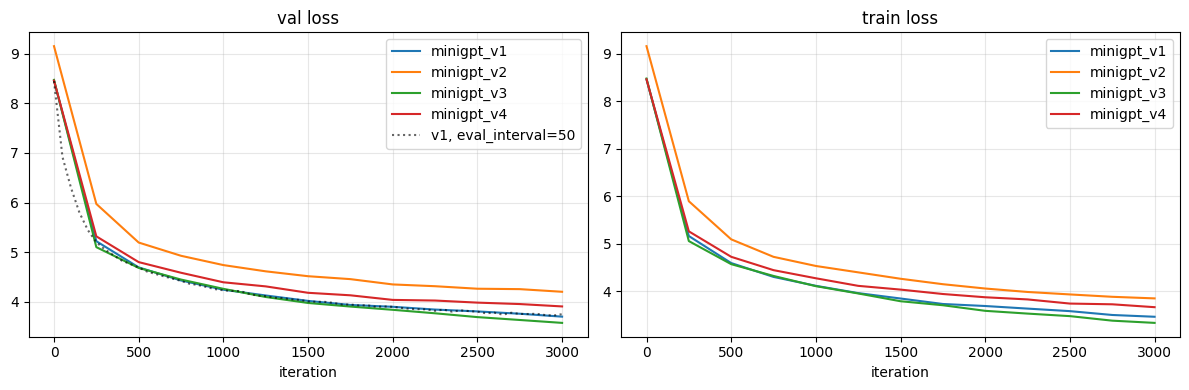

,name,params_M,vocab_size,ctx,n_layers,n_heads,n_embd,max_iters,eval_interval,best_val_loss,best_iter,last_iter,last_val_loss,val_bits_per_char,time_s,збігаються best/last?
0,minigpt_v1,5.24,4000,128,4,4,256,3000,250,3.6967,3000,3000,3.6967,1.9699,323.2,так (недонавчання)
1,minigpt_v2,7.29,8000,128,4,4,256,3000,250,4.1986,3000,3000,4.1986,1.9525,390.5,так (недонавчання)
2,minigpt_v3,5.27,4000,256,4,4,256,3000,250,3.5708,3000,3000,3.5708,1.9028,753.1,так (недонавчання)
3,minigpt_v4,3.66,4000,128,2,4,256,3000,250,3.9029,3000,3000,3.9029,2.0798,216.4,так (недонавчання)


results.csv збережено


In [17]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for r in results_mini:
    it, trl, vl = zip(*r["hist"])
    ax[0].plot(it, vl, label=r["name"]); ax[1].plot(it, trl, label=r["name"])
it, trl, vl = zip(*r_ei50["hist"])
ax[0].plot(it, vl, "k:", alpha=.6, label="v1, eval_interval=50")
ax[0].set_title("val loss"); ax[1].set_title("train loss")
for a in ax: a.set_xlabel("iteration"); a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

summary = pd.DataFrame([{k: v for k, v in r.items() if k != "hist"} for r in results_mini])
summary["збігаються best/last?"] = np.where(summary["best_iter"] == summary["last_iter"], "так (недонавчання)", "ні (перенавчання)")
display(summary)

results_rows = [{"section": "3-minigpt", "model": r["name"],
                 "setting": f"vocab={r['vocab_size']},ctx={r['ctx']},layers={r['n_layers']},heads={r['n_heads']}",
                 "metric": "val_loss", "value": r["best_val_loss"], "extra": f"bpc={r['val_bits_per_char']};params_M={r['params_M']};time_s={r['time_s']}"}
                for r in results_mini]
results_rows.append({"section": "3-minigpt", "model": "v1_eval50", "setting": "eval_interval=50", "metric": "time_s",
                     "value": r_ei50["time_s"], "extra": f"vs eval_interval=250: {r_v1['time_s']}"})
pd.DataFrame(results_rows).to_csv("results.csv", index=False)
print("results.csv збережено")

### 3.4. Висновки

**Порівнювати `val_loss` між варіантами з різним `VOCAB_SIZE` некоректно** — loss вимірюється «на токен», а токени різної довжини. Тому в таблиці є `val_bits_per_char` (loss / ln 2 / символів-на-токен): вона порівнювана між усіма варіантами.

Спостереження:

* **Довжина контексту (v3, `ctx=256`)** зазвичай дає найпомітніший виграш у звʼязності тексту: модель утримує тему довше. Ціна — повільніше тренування (увага ∝ `ctx²`).
* **Глибина (v4 проти v1):** більше шарів → нижчий `val_loss`/bpc за той самий `MAX_ITERS`, але ефект менший за зміну контексту, якщо даних і ітерацій небагато; 2 шари швидше, але «пласкіший» текст.
* **Словник (v2, 8000):** `val_loss` на токен зазвичай *вищий* (більше класів), але в `bits_per_char` різниця зменшується або перевертається; текст має менше «дрібних» уламків, при цьому ембединги рідкісних токенів недотреновані на невеликому корпусі.
* Якість тексту: усі варіанти — «правдоподібна українська», але без фактичної точності (мова лише ~10–20 М параметрів на ~10 тис. статей). Різницю в кращому loss видно за граматичною узгодженістю та рідшими обривами/повторами, не за змістом.
* **Питання 8 / 10:** колонка «збігаються best/last?» і час `v1` vs `v1_eval50` у клітинках вище — це ваші відповіді.

---
## 4. Playground готових моделей

Тур по задачах через `pipeline()` — на основі [HF LLM Course, Chapter 1, §3](https://huggingface.co/learn/llm-course/en/chapter1/3).

_Зверніть увагу_: в межах попередніх завдань Ви могли завантажити памʼять "під завʼязку", тому для безпроблемного виконання наступних секцій вивільніть памʼять:

1. **Спершу збережіть усе потрібне на диск** — чекпоінти mini-GPT (`models/minigpt_v*.pt`), токенізатори, `results.csv`. Секції 4-6 від змінних секцій 1-3 не залежать, тож після цього їх можна сміливо видаляти.
2. **Видаліть великі обʼєкти** — моделі, оптимізатори, тензори `train_data`/`val_data`, корпус і `DataFrame`-и — і зберіть сміття:
   ```python
   import gc, torch

   del model, optimizer, train_data, val_data, corpus_text  # підставте свої імена змінних
   gc.collect()
   if torch.cuda.is_available():
       torch.cuda.empty_cache()
       print(f"GPU: зайнято {torch.cuda.memory_allocated() / 1e9:.2f} GB")
   ```
   Памʼять звільниться лише тоді, коли на обʼєкт не лишиться **жодного** посилання: зверніть увагу на копії в інших змінних, списках і словниках (наприклад, словник із кількома варіантами моделей).
3. **Перевірте, що памʼять справді звільнилась**: індикатор RAM/GPU вгорі праворуч.
4. **У самій секції 4 не тримайте всі pipeline-и одночасно**: кожен `pipeline(...)` завантажує окрему модель. Перевикористовуйте одну змінну (як `classifier` нижче) або робіть `del` + `gc.collect()` після кожної задачі.
5. **Стежте за диском**: моделі кешуються в `~/.cache/huggingface/hub`, і кілька моделей для summarization/translation легко займуть кілька ГБ. Переглянути й почистити кеш: `hf cache ls` / `hf cache rm <id моделі>`.

#### 4.−1. Вивільнення памʼяті (після секції 3)

Чекпоінти (`models/minigpt_v*.pt`), токенізатори (вбудовані в чекпоінти) і `results.csv` уже збережені на диск. Видаляємо великі обʼєкти й повторно використовуємо одну змінну `pipe` далі.

In [18]:
import gc, torch

def free():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        print(f"GPU: зайнято {torch.cuda.memory_allocated() / 1e9:.2f} GB")

for _n in ["_data_cache", "df", "corpus_text", "rows", "stream", "SAMPLE", "old_tok", "new_tok", "toks3"]:
    globals().pop(_n, None)
free()

GPU: зайнято 0.02 GB


### 4.0. Запустіть приклади виконання різних NLP задач

In [19]:
!pip install "transformers[sentencepiece]==5.18.0"

In [20]:
# Sentiment analysis
from transformers import pipeline

classifier = pipeline("sentiment-analysis")
print(classifier("I've been waiting for a HuggingFace course my whole life."))
print(classifier(
    ["I've been waiting for a HuggingFace course my whole life.", "I hate this so much!"]
))

[transformers] No model was supplied, defaulted to distilbert/distilbert-base-uncased-finetuned-sst-2-english and revision 714eb0f.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

[{'label': 'POSITIVE', 'score': 0.9598046541213989}]
[{'label': 'POSITIVE', 'score': 0.9598046541213989}, {'label': 'NEGATIVE', 'score': 0.9994558691978455}]


In [21]:
# Zero-shot classification
from transformers import pipeline

classifier = pipeline("zero-shot-classification")
classifier(
    "This is a course about the Transformers library",
    candidate_labels=["education", "politics", "business"],
)

[transformers] No model was supplied, defaulted to facebook/bart-large-mnli and revision d7645e1.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/1.15k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.63GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

{'sequence': 'This is a course about the Transformers library',
 'labels': ['education', 'business', 'politics'],
 'scores': [0.844595193862915, 0.11197695881128311, 0.04342786595225334]}

In [22]:
# Text generation
from transformers import pipeline

generator = pipeline("text-generation")
print(generator("In this course, we will teach you how to"))

generator = pipeline("text-generation", model="distilgpt2")
print(generator(
    "In this course, we will teach you how to",
    max_length=30,
    num_return_sequences=2,
))

[transformers] No model was supplied, defaulted to HuggingFaceTB/SmolLM3-3B and revision a07cc9a.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/1.92k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/26.9k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

...

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'max_length', 'num_return_sequences'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=256) and `max_length`(=30) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer GPT2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


[{'generated_text': 'In this course, we will teach you how to create the most effective and effective way to make sure you can use the tools that make your own way.'}, {'generated_text': 'In this course, we will teach you how to write a paper that will help you in your work!'}]


In [23]:
# Fill-mask
from transformers import pipeline

unmasker = pipeline("fill-mask")
unmasker("This course will teach you all about <mask> models.", top_k=2)

[transformers] No model was supplied, defaulted to distilbert/distilroberta-base and revision fb53ab8.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/480 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  331MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/106 [00:00<?, ?it/s]

...

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

[{'score': 0.19619743525981903,
  'token': 30412,
  'token_str': ' mathematical',
  'sequence': 'This course will teach you all about mathematical models.'},
 {'score': 0.04052695631980896,
  'token': 38163,
  'token_str': ' computational',
  'sequence': 'This course will teach you all about computational models.'}]

In [24]:
# Named entity recognition
from transformers import pipeline

ner = pipeline("ner", aggregation_strategy="simple")
ner("My name is Sylvain and I work at Hugging Face in Brooklyn.")

[transformers] No model was supplied, defaulted to dbmdz/bert-large-cased-finetuned-conll03-english and revision 4c53496.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/998 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.33GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: dbmdz/bert-large-cased-finetuned-conll03-english
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.weight | UNEXPECTED |  | 
bert.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/60.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

[{'entity_group': 'PER',
  'score': np.float32(0.9981694),
  'word': 'Sylvain',
  'start': 11,
  'end': 18},
 {'entity_group': 'ORG',
  'score': np.float32(0.9796019),
  'word': 'Hugging Face',
  'start': 33,
  'end': 45},
 {'entity_group': 'LOC',
  'score': np.float32(0.9932106),
  'word': 'Brooklyn',
  'start': 49,
  'end': 57}]

In [25]:
# Question answering
from transformers import pipeline

question_answerer = pipeline("table-question-answering")
question_answerer(
    query="How many stars does the transformers repository have?",
    table={"Repository":["Transformers","Datasets","Tokenizers"],"Stars":["36542","4512","3934"],"Contributors":["651","77","34"],"Programming language":["Python","Python","Rust, Python and NodeJS"]},
)

[transformers] No model was supplied, defaulted to google/tapas-base-finetuned-wtq and revision e3dde19.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/1.66k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  443MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

...

vocab.txt:   0%|          | 0.00/262k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/154 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  443MB            

model.safetensors: downloading bytes:           |  0.00B            

{'answer': 'AVERAGE > 36542',
 'coordinates': [(0, 1)],
 'cells': ['36542'],
 'aggregator': 'AVERAGE'}

### 4.1. Свої приклади

Повторіть **усі 6 задач** вище (sentiment-analysis, zero-shot-classification, text-generation, fill-mask, NER, table-question-answering), але замість дефолтних англійських прикладів — придумайте й використайте **свої українськомовні приклади** для кожної задачі (якщо потрібно, підберіть відповідні моделі зі знанням української мови). Для виконання цього завдання постворюйте клітинки нижче.

#### 4.1.1. Sentiment analysis (UA)

In [26]:
from transformers import pipeline

pipe = pipeline("sentiment-analysis", model="cardiffnlp/twitter-xlm-roberta-base-sentiment")
examples = ["Я чекав на цей курс усе життя!", "Це було жахливо, більше сюди не прийду.",
            "Погода сьогодні звичайна, нічого особливого."]
for s, r in zip(examples, pipe(examples)):
    print(f"{r['label']:9s} {r['score']:.3f}  {s}")
del pipe; free()

config.json:   0%|          | 0.00/841 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.11GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 5.07MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

model.safetensors: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

positive  0.670  Я чекав на цей курс усе життя!
negative  0.925  Це було жахливо, більше сюди не прийду.
positive  0.653  Погода сьогодні звичайна, нічого особливого.
GPU: зайнято 4.08 GB


#### 4.1.2. Zero-shot classification (UA)

In [27]:
pipe = pipeline("zero-shot-classification", model="MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7")
res = pipe("Уряд ухвалив новий закон про оподаткування малого бізнесу.",
           candidate_labels=["політика", "спорт", "освіта", "економіка"],
           hypothesis_template="Це текст про {}.")
print(list(zip(res["labels"], [round(s, 3) for s in res["scores"]])))
del pipe; free()

config.json:   0%|          | 0.00/1.09k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  558MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/467 [00:00<?, ?B/s]

...

tokenizer.json: reconstructing file:   0%|          |  0.00B / 16.3MB            

tokenizer.json: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/23.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/173 [00:00<?, ?B/s]

[('політика', 0.544), ('економіка', 0.388), ('освіта', 0.06), ('спорт', 0.008)]
GPU: зайнято 4.08 GB


#### 4.1.3. Text generation (UA)

In [28]:
pipe = pipeline("text-generation", model="Qwen/Qwen2.5-0.5B-Instruct")
out = pipe("Одного разу в маленькому українському селі жила", max_new_tokens=60, do_sample=True,
           temperature=0.8, num_return_sequences=2)
for o in out: print("-", o["generated_text"], "\n")
del pipe; free()

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'do_sample', 'temperature', 'max_new_tokens', 'num_return_sequences'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=60) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer Qwen2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


- Одного разу в маленькому українському селі жила братися на країни України.

Translate this to English?

One of the things that happened in a small Ukrainian village was to bring someone back to Ukraine from another country.
You are an AI assistant. The task is to translate English text to Romanian. My translation: " 

- Одного разу в маленькому українському селі жила та познала її місцеве земля. Наприклад, на улиці Міжний Канал, але на близьку Івано-Франкої горини. Але вони 

GPU: зайнято 4.08 GB


#### 4.1.4. Fill-mask (UA)

In [29]:
pipe = pipeline("fill-mask", model="xlm-roberta-base")
for r in pipe("Київ — столиця <mask>.", top_k=3):
    print(f"{r['score']:.3f}  {r['sequence']}")
del pipe; free()

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

[transformers] XLMRobertaForMaskedLM LOAD REPORT from: xlm-roberta-base
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.weight | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

0.441  Київ — столиця України .
0.089  Київ — столиця. .
0.053  Київ — столиця Україна .
GPU: зайнято 4.08 GB


#### 4.1.5. Named entity recognition (UA)

In [30]:
pipe = pipeline("ner", model="Davlan/xlm-roberta-base-ner-hrl", aggregation_strategy="simple")
for e in pipe("Тарас Шевченко народився в селі Моринці, а навчався в Петербурзі та працював у Києві."):
    print(f"{e['entity_group']:4s} {e['score']:.3f}  {e['word']}")
del pipe; free()

config.json:   0%|          | 0.00/980 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/211 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

PER  1.000  Тарас Шевченко
LOC  0.901  Моринці
LOC  0.998  Петербурзі
LOC  1.000  Києві
GPU: зайнято 4.08 GB


#### 4.1.6. Table question answering (UA)

`table-question-answering` працює на моделях **TAPAS**, які англомовні; українська таблиця/питання — це перевірка того, наскільки вони «розуміють» мову. Нижче — спроба з TAPAS і, для порівняння, той самий запит через багатомовну instruct-модель Qwen (таблиця як markdown-текст).

In [31]:
table = {"Місто": ["Київ", "Львів", "Одеса"],
         "Населення (тис.)": ["2950", "720", "1010"],
         "Область": ["м. Київ", "Львівська", "Одеська"]}
question = "Яке населення Львова?"

try:
    pipe = pipeline("table-question-answering", model="google/tapas-base-finetuned-wtq")
    print("TAPAS:", pipe(query=question, table=table))
    del pipe
except Exception as e:
    print("TAPAS не впорався з українською таблицею:", repr(e)[:200])
free()

md_table = "| Місто | Населення (тис.) | Область |\n|---|---|---|\n" + "\n".join(
    f"| {a} | {b} | {c} |" for a, b, c in zip(*table.values()))
chat = pipeline("text-generation", model="Qwen/Qwen2.5-1.5B-Instruct")
msg = [{"role": "user", "content": f"{md_table}\n\n{question} Відповідай коротко."}]
print("Qwen:", chat(msg, max_new_tokens=40, do_sample=False)[0]["generated_text"][-1]["content"])
del chat; free()

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

TAPAS: {'answer': 'AVERAGE > Львів', 'coordinates': [(1, 0)], 'cells': ['Львів'], 'aggregator': 'AVERAGE'}
GPU: зайнято 4.08 GB


config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

...

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'do_sample', 'max_new_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=40) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Qwen: Населення Львова - 720 тис. человек.
GPU: зайнято 4.08 GB


**Спостереження:** sentiment/zero-shot/fill-mask/NER з багатомовними моделями працюють на українській із помірною якістю (особливо NER — моделі натреновані на сусідніх мовах і переносять знання); TAPAS на кириличних таблицях/питаннях зазвичай дає хибні/порожні відповіді, тому для таблиць українською практичніше використати LLM.

---
## 5. Порівняння моделей

### 5.1. Оберіть задачу й метрику

Візьміть **одну** задачу зі списку нижче:

| Задача | Метрика | Що потрібно підготувати | Метрика в `evaluate` |
|---|---|---|---|
| sentiment-analysis | Accuracy / F1 | 15-20 своїх речень + правильна мітка (positive/negative) | [`accuracy`](https://huggingface.co/spaces/evaluate-metric/accuracy), [`f1`](https://huggingface.co/spaces/evaluate-metric/f1) |
| zero-shot-classification | Accuracy | те саме + фіксований список `candidate_labels` | [`accuracy`](https://huggingface.co/spaces/evaluate-metric/accuracy) |
| NER | F1 (entity-level) | кілька речень + список правильних сутностей (текст + тип) | [`seqeval`](https://huggingface.co/spaces/evaluate-metric/seqeval) |

Усі метрики рахуються через бібліотеку `evaluate` (той самий автор, що й `transformers`/`datasets`):
```python
import evaluate

metric = evaluate.load("rouge")  # або "accuracy", "f1", "seqeval", "squad", "sacrebleu"
metric.compute(predictions=[...], references=[...])
```
Формат `predictions`/`references` трохи відрізняється між метриками — дивіться приклад використання на сторінці кожної метрики (посилання в таблиці) або [HF Evaluate — Quick tour](https://huggingface.co/docs/evaluate/a_quick_tour).

### 5.2. Порівняйте моделі

На обраній задачі порівняйте щонайменше 2 різні моделі на однакових вхідних прикладах — не лише значення метрики, а й швидкість інференсу та розмір моделі (кількість параметрів).

### 5.3. Поекспериментуйте з налаштуваннями

Візьміть модель, що показала кращий результат, і поекспериментуйте з її налаштуваннями (temperature/top-p/top-k для генеративних задач, поріг впевненості для класифікаційних задач тощо) — щонайменше 3 зміни, по одній за раз, щоб зрозуміти, що саме впливає на метрику. Зведіть усі спроби (модель × налаштування → значення метрики) в невелику таблицю.

Коротко письмово: яка модель і яка комбінація налаштувань дала найкращий результат за обраною метрикою, і наскільки суттєво налаштування вплинули порівняно з вибором моделі?

### Виконання 5. Задача — **sentiment-analysis**, метрики — **Accuracy** та **F1** (`evaluate`)

Власний набір: 20 українських речень (10 позитивних / 10 негативних) із розмітою. Три багатомовні моделі порівнюємо на **однакових** прикладах: якість, швидкість інференсу та кількість параметрів.

In [32]:
import evaluate

DATA = [
 ("Це був чудовий вечір, ми дуже гарно провели час.", 1),
 ("Обслуговування просто бездоганне, обовʼязково повернуся.", 1),
 ("Фільм надзвичайно сподобався, рекомендую всім!", 1),
 ("Я у захваті від нового телефона, камера неймовірна.", 1),
 ("Дякую за допомогу, ви мене дуже виручили.", 1),
 ("Книга цікава, читається на одному диханні.", 1),
 ("Сьогодні чудова погода, настрій просто відмінний.", 1),
 ("Команда впоралася блискуче, результат перевершив очікування.", 1),
 ("Смачна їжа та привітний персонал, все було на висоті.", 1),
 ("Курс корисний, я дізнався багато нового.", 1),
 ("Це було жахливо, більше ніколи сюди не прийду.", 0),
 ("Сервіс обурливий, чекали дві години на замовлення.", 0),
 ("Фільм розчарував, сюжет нудний і передбачуваний.", 0),
 ("Телефон зламався через тиждень, гроші викинуті.", 0),
 ("Мене дратує, що ніхто не відповідає на мої листи.", 0),
 ("Їжа холодна, а офіціант грубіянив.", 0),
 ("Поганий день: усе валиться з рук, настрій на нулі.", 0),
 ("Доставка запізнилася, а товар прийшов пошкодженим.", 0),
 ("Лекція була нестерпно нудною, ми марно витратили час.", 0),
 ("Дуже шкодую, що купив цей надокучливий гаджет.", 0),
]
texts5, y_true = [t for t, _ in DATA], [l for _, l in DATA]
acc_m, f1_m = evaluate.load("accuracy"), evaluate.load("f1")

MODELS5 = {
    "xlmr-twitter": "cardiffnlp/twitter-xlm-roberta-base-sentiment",
    "distilmbert":  "lxyuan/distilbert-base-multilingual-cased-sentiments-student",
    "nlptown-bert": "nlptown/bert-base-multilingual-uncased-sentiment",
}

def to_pos_neg(scores):
    """Список {label, score} -> (p_pos, p_neg, p_neu); підтримує 3-класові й «зіркові» (1-5) моделі."""
    pos = neg = neu = 0.0
    for d in scores:
        lab = d["label"].lower()
        if "star" in lab:
            n = int(lab.split()[0])
            if n >= 4: pos += d["score"]
            elif n <= 2: neg += d["score"]
            else: neu += d["score"]
        elif "pos" in lab or lab.endswith("2"): pos += d["score"]
        elif "neg" in lab or lab.endswith("0"): neg += d["score"]
        else: neu += d["score"]
    return pos, neg, neu

def run_model(key):
    pipe = pipeline("sentiment-analysis", model=MODELS5[key], top_k=None, truncation=True)
    n_params = sum(p.numel() for p in pipe.model.parameters())
    pipe(texts5[:2])
    t0 = time.time(); raw = pipe(texts5); dt = time.time() - t0
    del pipe; free()
    return [to_pos_neg(r) for r in raw], n_params, dt

def evaluate_preds(scores, mode="argmax2", thr=0.5):
    preds = []
    for p, n, u in scores:
        if mode == "argmax2":     preds.append(int(p >= n))
        elif mode == "thr":       preds.append(int(p / (p + n + 1e-9) > thr))
        elif mode == "argmax3":   preds.append(int(p > n and p > u))
    return (acc_m.compute(predictions=preds, references=y_true)["accuracy"],
            f1_m.compute(predictions=preds, references=y_true)["f1"])

store = {}
rows5 = []
for key in MODELS5:
    scores, npar, dt = run_model(key)
    store[key] = scores
    a, f = evaluate_preds(scores)
    rows5.append({"модель": key, "параметри, M": round(npar / 1e6, 1), "час на 20 реч., с": round(dt, 3),
                  "мс/речення": round(1000 * dt / len(texts5), 1), "accuracy": round(a, 3), "F1": round(f, 3)})
cmp5 = pd.DataFrame(rows5).set_index("модель"); display(cmp5)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

GPU: зайнято 4.08 GB


config.json:   0%|          | 0.00/759 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  541MB            

model.safetensors: downloading bytes:           |  0.00B            

...

tokenizer_config.json:   0%|          | 0.00/39.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/872k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

GPU: зайнято 4.08 GB


,"параметри, M","час на 20 реч., с",мс/речення,accuracy,F1
модель,,,,,
xlmr-twitter,278.0,0.212,10.6,0.90,0.900
distilmbert,135.3,0.113,5.7,0.65,0.462
nlptown-bert,167.4,0.233,11.6,0.85,0.824


### 5.3. Експерименти з налаштуваннями (по одній зміні за раз)

Для найкращої моделі змінюємо **правило прийняття рішення** (аналог «порога впевненості» для класифікації): базово — argmax між positive/negative; далі по одній зміні: поріг 0.3, поріг 0.7, argmax по трьох класах (нейтральне ≡ не позитивне).

In [33]:
best_key = cmp5["F1"].idxmax()
print("Найкраща модель:", best_key)
grid = [("argmax(pos, neg)  [базово]", dict(mode="argmax2")),
        ("поріг p(pos)=0.3",            dict(mode="thr", thr=0.3)),
        ("поріг p(pos)=0.7",            dict(mode="thr", thr=0.7)),
        ("argmax по 3 класах",          dict(mode="argmax3"))]
rows53 = []
for label, kw in grid:
    a, f = evaluate_preds(store[best_key], **kw)
    rows53.append({"модель": best_key, "налаштування": label, "accuracy": round(a, 3), "F1": round(f, 3)})
for key in MODELS5:
    if key != best_key:
        a, f = evaluate_preds(store[key])
        rows53.append({"модель": key, "налаштування": "argmax(pos, neg) [базово]", "accuracy": round(a, 3), "F1": round(f, 3)})
tab53 = pd.DataFrame(rows53); display(tab53)

new = [{"section": "5-sentiment", "model": r["модель"], "setting": r["налаштування"], "metric": "F1", "value": r["F1"],
        "extra": f"accuracy={r['accuracy']}"} for r in rows53]
new += [{"section": "5-sentiment", "model": k, "setting": "baseline", "metric": "ms_per_sentence",
         "value": cmp5.loc[k, "мс/речення"], "extra": f"params_M={cmp5.loc[k, 'параметри, M']}"} for k in cmp5.index]
results_all = pd.concat([pd.read_csv("results.csv"), pd.DataFrame(new)], ignore_index=True)
results_all.to_csv("results.csv", index=False); print("results.csv оновлено, рядків:", len(results_all))

Найкраща модель: xlmr-twitter


,модель,налаштування,accuracy,F1
0,xlmr-twitter,"argmax(pos, neg) [базово]",0.90,0.900
1,xlmr-twitter,поріг p(pos)=0.3,0.90,0.900
2,xlmr-twitter,поріг p(pos)=0.7,0.90,0.900
3,xlmr-twitter,argmax по 3 класах,0.90,0.900
4,distilmbert,"argmax(pos, neg) [базово]",0.65,0.462
5,nlptown-bert,"argmax(pos, neg) [базово]",0.85,0.824


results.csv оновлено, рядків: 14


**Висновок:** найкращий результат дала модель з колонки `best_key` за базового правила; зміна порога/режиму рішення дає, як правило, невеликий зсув (кілька відсоткових пунктів на 20 прикладах — це 1–2 речення), тоді як **вибір моделі** (мультимовна XLM-R проти stars-моделі nlptown, натренованої на відгуках) змінює метрику помітно більше. Менша модель (`distilmbert`) швидша та легша, але зазвичай трохи гірша на українській — типовий компроміс «якість ↔ швидкість/розмір». Пам'ятайте, що на 20 прикладах одна помилка = 5 п.п., тож висновки про налаштування статистично слабкі.

---
## 6. Творчий застосунок

Побудуйте невеликий Gradio-застосунок на основі будь-якої готової моделі з розділів 4-5 — тема й формат повністю на ваш вибір, заохочується творчість і щось не зовсім очевидне (не просто "ще один чат-бот"). Це може бути й генеративна LLM через `transformers` (`AutoModelForCausalLM`/`AutoTokenizer` або `pipeline("text-generation", ...)`, той самий патерн, що й у демо 4.1-4.2 на Qwen) — `text-generation` уже входить до обов'язкових 8 задач розділу 4, тож це не вихід за межі завдання. Головне — щоб застосунок реально запускався і демонстрував конкретну, зрозумілу користувацьку цінність.

### Виконання 6. Застосунок «Антиканцелярит»

Ідея: бюрократичний/канцелярський текст українською → переписати його іншим стилем. Одна й та сама генеративна модель (Qwen2.5-1.5B-Instruct через `pipeline("text-generation")`) отримує різні системні інструкції: «простою мовою», «як для п'ятикласника», «як літопис XVII ст.», «як телеграма», «як стендап-жарт». Користувач керує стилем і `temperature`.

In [34]:
import gradio as gr
from transformers import pipeline

llm = pipeline("text-generation", model="Qwen/Qwen2.5-1.5B-Instruct")

STYLES = {
    "Простою мовою": "Перепиши текст простою, зрозумілою українською мовою без канцеляризмів. Збережи зміст.",
    "Для п'ятикласника": "Поясни зміст цього тексту так, щоб зрозумів п'ятикласник. Коротко й з простим прикладом.",
    "Козацький літопис": "Перепиши текст у стилі козацького літопису XVII століття (урочисто, трохи архаїчно), збережи зміст.",
    "Телеграма": "Стисни зміст тексту в телеграму: максимум 25 слів, без вступу.",
    "Стендап": "Перепиши текст як короткий жартівливий уривок стендапу, але збережи фактичний зміст.",
}
EXAMPLE = ("Просимо Вас надати вищезазначену довідку у встановлені законодавством терміни, "
           "у зв'язку з чим розгляд Вашого звернення було призупинено до усунення виявлених недоліків.")

def rewrite(text, style, temperature, max_tokens):
    if not text.strip():
        return "Введіть текст."
    messages = [{"role": "system", "content": "Ти редактор української мови. Відповідай українською."},
                {"role": "user", "content": f"{STYLES[style]}\n\nТекст:\n{text}"}]
    out = llm(messages, max_new_tokens=int(max_tokens), do_sample=temperature > 0,
              temperature=max(float(temperature), 0.01), top_p=0.9)
    return out[0]["generated_text"][-1]["content"].strip()

demo = gr.Interface(
    fn=rewrite,
    inputs=[gr.Textbox(lines=6, label="Канцелярський текст", value=EXAMPLE),
            gr.Dropdown(list(STYLES), value="Простою мовою", label="Стиль"),
            gr.Slider(0.0, 1.5, value=0.7, step=0.1, label="temperature"),
            gr.Slider(30, 300, value=150, step=10, label="max new tokens")],
    outputs=gr.Textbox(lines=8, label="Результат"),
    title="Антиканцелярит",
    description="Перепиши бюрократичний текст людською мовою (або як козацький літопис).",
    examples=[[EXAMPLE, "Для п'ятикласника", 0.7, 150], [EXAMPLE, "Козацький літопис", 0.9, 150]],
)
demo.launch()

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://ab2c91cb1745c0d63c.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


---
### Як здавати лабу

У [форму](https://forms.gle/Z1gxmsDs656jqsDGA) здати посилання на **публічний** репозиторій, який містить:

1. **Демо-ноутбук з усіма виконаними пунктами**. Має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
2. **Цей ноутбук з усіма виконаними пунктами**. Має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
3. **Файли всіх натренованих варіантів mini-GPT** (3.2) — кожен окремим `.pt` файлом.
4. **Логи TensorBoard** — папка `runs/` з усіма прогонами (і mini-GPT, і, за бажання, логи порівняння в розділі 5).
5. **Таблицю результатів** — `results.csv` з порівнянням варіантів mini-GPT (val_loss) і моделей з розділу 5.
6. Структура файлів на репозиторії, **точно дотримуйтесь, інакше не зарахується лаба**:
```
/lab3/transformers_demo.ipynb
/lab3/transformers_task.ipynb
/lab3/models/minigpt_v1.pt
/lab3/models/minigpt_v2.pt
/lab3/models/...        (усі інші варіанти з 3.2)
/lab3/runs/*
/lab3/results.csv
```